In [ ]:
   import os
   os.environ["PA1_PRESET"] = "full"

# Task 1 — Forecasting Across Heterogeneous Sensors

AI651 / CS434 / EE5108 · implementation notebook

Use the Task 1 handout in `main.pdf` for concepts and response instructions. This notebook
contains the implementations, checks, and outputs for each part.

The simulated setting is a 20 Hz four-station production line. Products A, B, and C set global
nominal pace ranges of 14--18, 21--27, and 28--36 samples; each operating run has one actual pace from
its product range. Stations 1--3 are established and station 4 is held out.

Write every assessed response in your report. Each part has its own simple rhythm:
inspect its **Outputs**, then write its named **Response**.

| Part | You implement | Outputs | Response |
| --- | --- | --- | --- |
| 0. The World and Forecasting Setup | — | — | — |
| 1. Context-Dependent Forecasting | Raw Attention forecaster | 1.1–1.3 | 1A, 1B |
| 2. Separate Slow Structure from Repetition | `SeriesDecomposition.forward` | 2.1–2.3 | 2 |
| 3. Mix by Temporal Delay | `aggregate_delays` (`delay_scores` is supplied) | 3.1–3.2 | 3 |
| 4. Compare Designs and Deploy | — | 4.1–4.3 | 4 |

Short-horizon vibration forecasts provide the expected near-term baseline for condition monitoring.
Deviations from that expected behavior can indicate abnormal operation.

**Every implementation is checked where you write it.** Each implementation has a clear contract
and an immediate check; the numerical components also include small worked examples. Checks test
values, shapes, and gradients and name the likely cause when they fail. Nothing is left for a
training run to discover.


## 0. The World and Forecasting Setup

**Physical line:** Station 1 → Station 2 → Station 3 → Station 4. Each station has one vibration
accelerometer sampled at 20 Hz. Stations 1–3 are established; Station 4 is held out from fitting
but still supplies its own 96-sample context at inference time.

| Product | Actual pace in each operating run |
| --- | --- |
| A | 14–18 samples per cycle |
| B | 21–27 samples per cycle |
| C | 28–36 samples per cycle |

Each reading combines a slow drift, a repeating vibration, and small noise. A forecast receives
`L=96` readings from one station and predicts `H=48` future readings. Windows never cross a product
changeover. Train is samples 0–9600, validation is 9600–12480, and final test is 12480–15360.
Anchoring and scaling are supplied and use established-station training data only.

### Environment setup

Use Python 3.11 or later. From the unzipped assignment directory:

```bash
python -m venv .venv
# Linux/macOS:
source .venv/bin/activate
# Windows PowerShell:
# .venv\Scripts\Activate.ps1
python -m pip install -r requirements.txt
jupyter lab
```

For CPU-only PyTorch, install it from its CPU wheel index before installing the remaining
requirements:

```bash
python -m pip install torch --index-url https://download.pytorch.org/whl/cpu
python -m pip install -r requirements.txt
```

Keep `harness/` and `requirements.txt` beside this notebook.

#### Important: The notebook starts with PA1_PRESET=smoke only to make implementation and debugging fast. All results used in your report must come from a fresh PA1_PRESET=full run.

In [ ]:
import os, glob, shutil
os.makedirs("harness", exist_ok=True)
for f in glob.glob("*.py"):
    if os.path.basename(f).startswith("design_"):
        shutil.move(f, os.path.join("harness", os.path.basename(f)))
print("harness/ contains:", sorted(os.listdir("harness")))

harness/ contains: []


In [ ]:
import os
import math
import sys
from pathlib import Path

for candidate in (Path("harness"), Path("PA 01/harness"), Path("../harness")):
    if candidate.is_dir():
        sys.path.insert(0, str(candidate.resolve()))
        break
else:
    raise FileNotFoundError("Keep harness/ beside this notebook and start Jupyter there.")

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display
import design_controls as design
import design_data as data
import design_diagnostics as figures
import design_reporting as report

preset = os.environ.get("PA1_PRESET", "smoke")
seed = int(os.environ.get("PA1_SEED", "0"))
model_seed = int(os.environ.get("PA1_MODEL_SEED", str(seed)))
study = design.Study(preset, seed, model_seed=model_seed)
assert design.check_world(study.world)
print(f"preset={preset}; data seed={seed}; model seed={model_seed}; device={design.device}")
print(f"sampling rate={data.SAMPLING_RATE_HZ:g} Hz; products={', '.join(study.world.product_names)}")
print(f"product pace ranges={study.world.product_period_bands.tolist()} samples; "
      f"established stations={study.established.sum()}; held-out station=4")
print(f"eligible train/validation/test origins: "
      f"{len(study.region('train')['origins'])}/"
      f"{len(study.region('validation')['origins'])}/"
      f"{len(study.region('test')['origins'])}")



Four-station product-line world checks passed.
preset=full; data seed=0; model seed=0; device=cuda
sampling rate=20 Hz; products=Product A, Product B, Product C
product pace ranges=[[14.0, 18.0], [21.0, 27.0], [28.0, 36.0]] samples; established stations=3; held-out station=4
eligible train/validation/test origins: 650/105/105


In [ ]:
import time  # used by the instrumented trainer below

# ---- hyperparameters actually in force (labelled), pulled from the harness -----
print("Fit configuration (design.FIT_CONFIGURATION):")
for _k, _v in design.FIT_CONFIGURATION.items():
    print(f"    {_k:22s} = {_v}")
print(f"Active preset '{study.preset_name}':")
for _k, _v in vars(study.preset).items():
    print(f"    {_k:22s} = {_v}")
print(f"Model width d = {study.preset.width}, encoder layers = {study.preset.layers}, "
      f"heads = 4, dropout = 0.1")
print(f"Selected decomposition kernel m = {study.decomposition_kernel} "
      f"(oracle-chosen from {tuple(design.DECOMPOSITION_CANDIDATES)}); "
      f"ridge lambda = {study.ridge_lambda:g}")
print(f"Fixed scale c (established-train std of consecutive diffs) = {study.scale:.4f} m/s²")


def full_metric_frame(study, model, region="validation"):
    """Every handout metric, in physical units, per population x product.

    Predicts on ALL four stations of `region`, un-scales to m/s², and reports
    MSE / RMSE / MAE for established stations 1-3 and held-out station 4, both
    overall and per product. This is a read-out only; it fits nothing.
    """
    part = study.region(region)
    # INPUT-VECTOR CONSTRUCTION for inference: the region already stores the
    # anchored, scaled contexts x = (context - last_value) / scale with shape
    # [n_sensors, n_windows, L]. Flatten sensors/windows into a batch of [., L, 1].
    context_batch = part["x"].reshape(-1, data.CONTEXT, 1).astype(np.float32)
    scaled = design._predict(model, context_batch).reshape(
        part["x"].shape[:2] + (data.HORIZON,))
    # transform back to reading units: multiply by the fixed scale, restore anchor.
    prediction = scaled * study.scale + part["anchor"]           # [n_sensors, n_windows, H]
    target = part["target"]
    rows = []
    for population, label in (("established", "established stations 1-3"),
                              ("held-out", "held-out station 4")):
        for product in ("(all products)",) + tuple(study.world.product_names):
            keep = study.mask(population, region)
            if product != "(all products)":
                keep = keep & study.mask(product, region)
            if keep.sum() == 0 or np.isnan(prediction[keep]).any():
                mse = rmse = mae = np.nan
            else:
                pred_sel, tgt_sel = prediction[keep], target[keep]
                mse = data.mse(pred_sel, tgt_sel)
                rmse = data.rmse(pred_sel, tgt_sel)
                mae = data.mae(pred_sel, tgt_sel)
            rows.append({"population": label, "product": product, "windows": int(keep.sum()),
                         "MSE (m/s²)²": mse, "RMSE (m/s²)": rmse, "MAE (m/s²)": mae})
    return pd.DataFrame(rows)


def train_verbose(study, name, rounds=8, cache=False, **kwargs):
    """Leakage-safe fit identical to study.train, but printing the FULL metric
    panel every reporting round. Registers the fitted model into `study`.

    Selection metric = established validation MSE (normalised), exactly as the
    supplied harness. Held-out / per-product numbers are diagnostics only; the
    test region is never read here.
    """
    fit = design.FIT_CONFIGURATION
    preset = study.preset
    device = design.device

    # ---- build the model exactly as study.train does (same seed + settings) ----
    torch.manual_seed(5000 + study.model_seed)
    settings = study.settings(name, **kwargs)
    model = design.models.build(name, **settings).to(device)

    # ---- established-only tensors (fitting + selection); nothing else fits ------
    xt, yt = study.tensors("train")             # anchored/scaled established train
    xv, yv = study.tensors("validation")        # anchored/scaled established validation
    X, Y = torch.as_tensor(xt, device=device), torch.as_tensor(yt, device=device)

    # ---- optimiser / schedule = the labelled fit configuration -----------------
    optimizer = torch.optim.AdamW(model.parameters(), lr=fit["learning_rate"],
                                  weight_decay=fit["weight_decay"])
    schedule = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=fit["max_learning_rate"], total_steps=preset.steps,
        pct_start=fit["pct_start"])
    generator = torch.Generator().manual_seed(2000 + study.model_seed)

    every = max(1, preset.steps // rounds)      # reporting cadence
    best, state, done, exposure, curve, running = float("inf"), None, 0, 0, [], []
    started = time.perf_counter()
    print(f"\n===== train_verbose('{name}') : {preset.steps} steps, "
          f"batch {preset.batch}, reporting every {every} steps =====")

    while done < preset.steps:
        for index in torch.randperm(len(X), generator=generator).split(preset.batch):
            model.train()
            optimizer.zero_grad(set_to_none=True)
            loss = (model(X[index.to(device)]) - Y[index.to(device)]).square().mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite training loss")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), fit["gradient_clip_norm"])
            optimizer.step()
            schedule.step()
            done += 1
            exposure += len(index)
            running.append(float(loss))
            if done % every == 0 or done == preset.steps:
                # ---- SELECTION metric: established validation MSE (normalised) --
                val_mse = float(((design._predict(model, xv) - yv) ** 2).mean())
                curve.append((done, exposure, val_mse))
                is_best = val_mse < best
                if is_best:
                    best = val_mse
                    state = {k: v.detach().cpu().clone()
                             for k, v in model.state_dict().items()}
                # ---- COMPREHENSIVE per-round panel (physical units) ------------
                lr_now = schedule.get_last_lr()[0]
                print(f"\n[{name}] round: step {done}/{preset.steps} | windows seen "
                      f"{exposure} | lr {lr_now:.2e} | mean train MSE(norm) "
                      f"{np.mean(running):.4f} | est. val MSE(norm) {val_mse:.4f}"
                      f"{'  <-- new best checkpoint' if is_best else ''} | "
                      f"{time.perf_counter()-started:.1f}s")
                display(full_metric_frame(study, model, "validation").round(4))
                running = []
            if done >= preset.steps:
                break

    model.load_state_dict(state)                # restore the best-validation checkpoint
    seconds = time.perf_counter() - started
    parameters = sum(p.numel() for p in model.parameters())
    record = dict(model=name, steps=done, exposure=exposure, seconds=seconds,
                  curve=curve, best=best, parameters=parameters, device=str(device))
    # register into the study so every downstream Output uses this fitted model
    study._models[name] = model.to(device).eval()
    study._runs[name] = record
    study._model_signatures[name] = ("train_verbose", name)
    print(f"\n[{name}] DONE: {parameters} trainable parameters, {seconds:.1f}s, "
          f"best established-validation MSE = {best*study.scale**2:.4f} (m/s²)² "
          f"= RMSE {np.sqrt(best)*study.scale:.4f} m/s² (physical units).")
    return model

Fit configuration (design.FIT_CONFIGURATION):
    optimizer              = AdamW
    learning_rate          = 0.003
    weight_decay           = 0.0001
    scheduler              = OneCycleLR
    max_learning_rate      = 0.003
    pct_start              = 0.15
    gradient_clip_norm     = 5.0
    best_state_metric      = established validation MSE
Active preset 'full':
    stride_train           = 4
    stride_eval            = 8
    steps                  = 6000
    width                  = 64
    layers                 = 2
    batch                  = 128
Model width d = 64, encoder layers = 2, heads = 4, dropout = 0.1
Selected decomposition kernel m = 41 (oracle-chosen from (17, 25, 33, 41)); ridge lambda = 0.1
Fixed scale c (established-train std of consecutive diffs) = 0.4253 m/s²


## 1. Context-Dependent Forecasting

The handout ends Part 1 by wrapping Attention in an encoder and naming the result
**Raw Attention**: the forecaster every later section improves. Building it is your first
implementation, and it has to exist before any of Part 1's evidence can be produced.

Before the comparison, write the ordering you expect for **Response 1A**.

Produces **Outputs 1.1–1.3** → used in **Responses 1A and 1B**.


### Assemble the forecaster

At this point there is only one model: **Raw Attention**. It embeds the raw context, uses
Attention to mix positions, then predicts the next 48 readings.

Routine layers are complete. **You write the `RawAttentionForecaster.forward` assembly.**
Input `context` is `[B, L, 1]`; `self.embed` wants `[B, channels, L]` and returns `[B, d, L]`;
the encoder blocks use `[B, L, d]`; flatten that final representation before the forecast head
to return `[B, H]`.

The next cell immediately checks the output shape and gradient flow.


In [ ]:
class DenseAttention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        if d % heads:
            raise ValueError("width must be divisible by heads")
        self.heads = heads
        self.query, self.key, self.value = (nn.Linear(d, d) for _ in range(3))
        self.out = nn.Linear(d, d)
        self.last_attention = None

    def forward(self, x):                       # [B,L,d]
        batch, length, width = x.shape
        shape = (batch, length, self.heads, width // self.heads)
        q, k, v = (layer(x).view(shape).transpose(1, 2)
                   for layer in (self.query, self.key, self.value))  # [B,h,L,d_h]
        weights = (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)
        self.last_attention = weights.detach()  # [B,h,L,L]
        mixed = (weights @ v).transpose(1, 2).reshape(batch, length, width)
        return self.out(mixed)                  # [B,L,d]

class RawAttentionBlock(nn.Module):
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.mix = DenseAttention(d, heads)
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.feed_forward = nn.Sequential(
            nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, x):                       # [B,L,d]
        x = x + self.drop(self.mix(self.norm1(x)))
        return x + self.drop(self.feed_forward(self.norm2(x)))

class RawAttentionForecaster(nn.Module):
    # -------------------------------------------------------------------------
    # HYPERPARAMETERS (labelled). These defaults are the ones the Study harness
    # overrides per preset via study.settings(...):
    #   context = 96   L, input window length (samples)  -- FIXED by the task
    #   horizon = 48   H, forecast length (samples)      -- FIXED by the task
    #   channels = 1   one accelerometer value per time step
    #   d        = 64  model width (embedding size)      -- preset "full"
    #   heads    = 4   number of Attention heads (d must divide by heads)
    #   layers   = 2   number of encoder blocks          -- preset "full"
    #   dropout  = 0.1 dropout inside blocks / feed-forward
    # -------------------------------------------------------------------------
    def __init__(self, context=96, horizon=48, channels=1, d=64, heads=4, layers=2,
                 dropout=0.1):
        super().__init__()
        # embed: a length-3 circular Conv1d lifts the 1-channel context to width d.
        # Circular padding matches the "the last sample is adjacent to the first"
        # convention the delay mixer also uses, and keeps the sequence length = L.
        self.embed = nn.Conv1d(channels, d, 3, padding=1, padding_mode="circular", bias=False)
        # learned absolute position embedding, one vector per context position.
        self.position = nn.Parameter(torch.randn(1, context, d) * 0.02)
        self.blocks = nn.ModuleList([RawAttentionBlock(d, heads, dropout)
            for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        # forecast head: flatten the whole encoded [B, L, d] window (L*d features)
        # and map it linearly to the H future values.
        self.forecast_head = nn.Linear(context * d, horizon)

    def forward(self, context):                 # context [B,L,1] -> return [B,H]
        # ============================ IMPLEMENTATION ============================
        # INPUT-VECTOR CONSTRUCTION, step by step (shapes annotated on the right):
        #  1. Conv1d wants [B, channels, L]; the supplied context is [B, L, 1],
        #     so transpose (1,2) -> [B, 1, L], convolve -> [B, d, L].
        encoded = self.embed(context.transpose(1, 2))          # [B, d, L]
        #  2. Transpose back to the sequence layout the encoder blocks expect,
        #     [B, L, d], and add the learned position embedding (broadcast over B).
        encoded = encoded.transpose(1, 2) + self.position      # [B, L, d]
        #  3. Pass through every Attention+feed-forward encoder block in turn.
        #     Each block recomputes its own L*L Attention weights from THIS window,
        #     so the value-mixing operation is rebuilt per context (Response 1B).
        for block in self.blocks:
            encoded = block(encoded)                            # [B, L, d]
        #  4. Final LayerNorm, then flatten the [B, L, d] representation into one
        #     [B, L*d] feature vector per example and read off the H-step forecast.
        encoded = self.norm(encoded)                           # [B, L, d]
        return self.forecast_head(encoded.flatten(1))          # [B, H]
        # =======================================================================
    @property
    def attention_layers(self):
        return [block.mix for block in self.blocks if isinstance(block.mix, DenseAttention)]


In [ ]:
assert design.check_raw_attention_assembly(RawAttentionForecaster)
design.register_components(raw_forecaster_type=RawAttentionForecaster)


Raw-Attention assembly and gradient checks passed.


### Evidence

| Cell below | Output | Read it for |
| --- | --- | --- |
| fit Raw Attention, then compare four forecasters | 1.1 | Response 1A — then revise the ordering you wrote |
| the same station under two products | 1.2 | Response 1B |
| Attention behaviour across two contexts | 1.3 | Response 1B |

The three ridge forecasters are supplied; you implement nothing for them.


In [ ]:
# Fit Raw Attention with the comprehensive per-round metric panel, then Output 1.1.
train_verbose(study, "Raw Attention")
report.publish("1.1", report.comparison(
    study, ["Shared ridge", "Sensor-specific ridge", "Period-routed ridge", "Raw Attention"]))


===== train_verbose('Raw Attention') : 6000 steps, batch 128, reporting every 750 steps =====


/tmp/ipykernel_6430/589864670.py:103: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  running.append(float(loss))



[Raw Attention] round: step 750/6000 | windows seen 91492 | lr 2.81e-03 | mean train MSE(norm) 7.1136 | est. val MSE(norm) 4.0173  <-- new best checkpoint | 8.5s


,population,product,windows,MSE (m/s²)²,RMSE (m/s²),MAE (m/s²)
0,established stations 1-3,(all products),315,0.7267,0.8525,0.6431
1,established stations 1-3,Product A,105,0.8161,0.9034,0.6804
2,established stations 1-3,Product B,105,0.7850,0.8860,0.6709
3,established stations 1-3,Product C,105,0.5791,0.7610,0.5779
4,held-out station 4,(all products),105,1.5658,1.2513,0.9764
5,held-out station 4,Product A,35,1.7078,1.3068,1.0285
6,held-out station 4,Product B,35,1.5087,1.2283,0.9476
7,held-out station 4,Product C,35,1.4810,1.2170,0.9531



[Raw Attention] round: step 1500/6000 | windows seen 182886 | lr 2.90e-03 | mean train MSE(norm) 1.5749 | est. val MSE(norm) 1.8832  <-- new best checkpoint | 14.5s


...

,population,product,windows,MSE (m/s²)²,RMSE (m/s²),MAE (m/s²)
0,established stations 1-3,(all products),315,0.1713,0.4139,0.3118
1,established stations 1-3,Product A,105,0.1585,0.3981,0.3006
2,established stations 1-3,Product B,105,0.1901,0.4360,0.3281
3,established stations 1-3,Product C,105,0.1652,0.4065,0.3067
4,held-out station 4,(all products),105,0.3966,0.6298,0.4694
5,held-out station 4,Product A,35,0.4049,0.6363,0.4803
6,held-out station 4,Product B,35,0.3452,0.5875,0.4412
7,held-out station 4,Product C,35,0.4396,0.6630,0.4865



[Raw Attention] round: step 6000/6000 | windows seen 731250 | lr 1.23e-08 | mean train MSE(norm) 0.1816 | est. val MSE(norm) 0.9446  <-- new best checkpoint | 50.1s


,population,product,windows,MSE (m/s²)²,RMSE (m/s²),MAE (m/s²)
0,established stations 1-3,(all products),315,0.1709,0.4134,0.3113
1,established stations 1-3,Product A,105,0.1585,0.3981,0.3003
2,established stations 1-3,Product B,105,0.1904,0.4364,0.3292
3,established stations 1-3,Product C,105,0.1637,0.4046,0.3046
4,held-out station 4,(all products),105,0.3918,0.6259,0.4685
5,held-out station 4,Product A,35,0.3989,0.6316,0.4782
6,held-out station 4,Product B,35,0.3382,0.5816,0.4406
7,held-out station 4,Product C,35,0.4382,0.6619,0.4868



[Raw Attention] DONE: 368368 trainable parameters, 50.1s, best established-validation MSE = 0.1709 (m/s²)² = RMSE 0.4134 m/s² (physical units).
Output 1.1


,model,established stations RMSE (m/s²),established stations MSE (m/s²)²,"established stations, Product A RMSE","established stations, Product B RMSE","established stations, Product C RMSE",held-out station 4 RMSE (m/s²),held-out station 4 MSE (m/s²)²,"held-out station 4, Product A RMSE","held-out station 4, Product B RMSE","held-out station 4, Product C RMSE",parameters,fit seconds
0,Shared ridge,0.767,0.588,0.805,0.854,0.621,0.876,0.767,0.909,0.982,0.713,4608,0.002
1,Sensor-specific ridge,0.768,0.590,0.804,0.852,0.630,unavailable,unavailable,unavailable,unavailable,unavailable,13824,0.066
2,Period-routed ridge,0.166,0.028,0.181,0.164,0.152,0.173,0.03,0.184,0.182,0.15,59904,0.008
3,Raw Attention,0.413,0.171,0.398,0.436,0.405,0.626,0.392,0.632,0.582,0.662,368368,50.100


Output 1.2


,station,product,actual period (samples),model,window RMSE (m/s²)
0,1,Product A,16.135,Shared ridge,0.779
1,1,Product A,16.135,Sensor-specific ridge,0.787
2,1,Product A,16.135,Period-routed ridge,0.232
3,1,Product A,16.135,Raw Attention,0.251
4,1,Product C,30.093,Shared ridge,0.448
5,1,Product C,30.093,Sensor-specific ridge,0.436
6,1,Product C,30.093,Period-routed ridge,0.150
7,1,Product C,30.093,Raw Attention,0.354


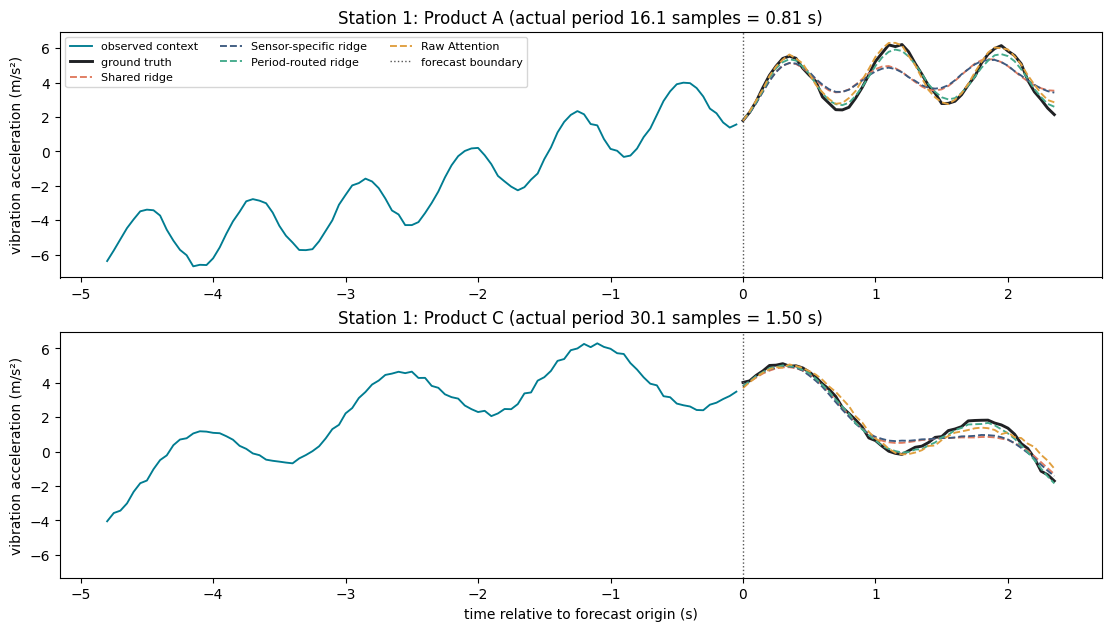

In [ ]:
report.publish("1.2", figures.regime_forecasts(
    study, ["Shared ridge", "Sensor-specific ridge", "Period-routed ridge", "Raw Attention"]))


Output 1.3


,station,product,actual period (samples),mean |Attention weight difference|,max |Attention weight difference|
0,1,Product A,16.135,unavailable,unavailable
1,1,Product C,30.093,unavailable,unavailable
2,1,Product A vs Product C (difference),unavailable,0.012,0.387


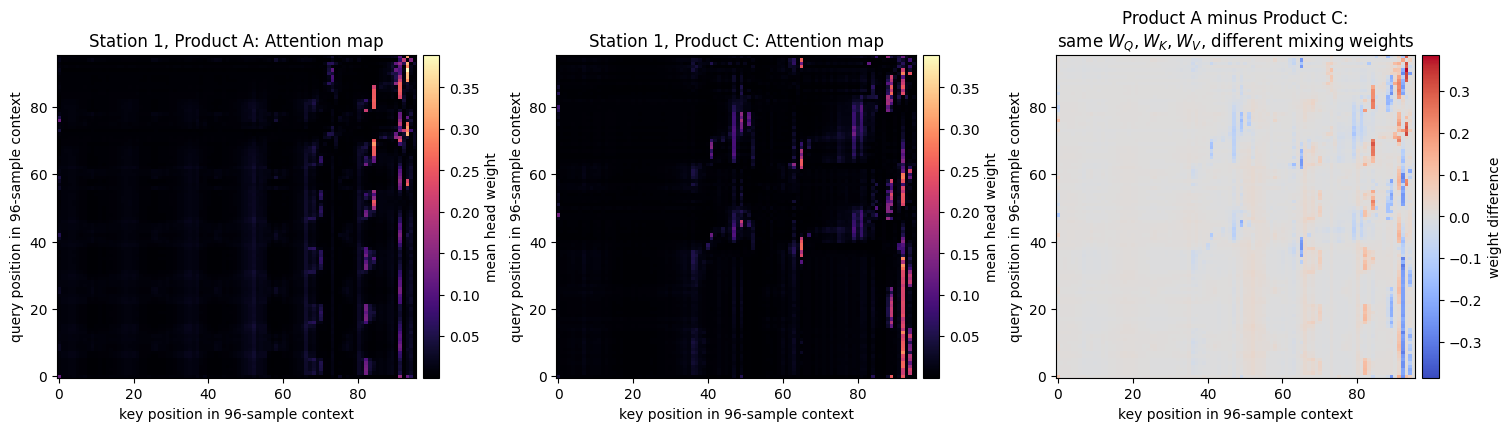

In [ ]:
report.publish("1.3", figures.attention_behaviour(study))


## 2. Separate Slow Structure from Repetition

Switch 1. Across a 96-sample window the slow part of a reading is a smooth ramp, and it costs the
forecaster twice: the encoder spends representation on it, and it can hide the repeating
vibration. Splitting the context sends each stream to the part of the model suited to it, while
leaving the Attention mixer itself alone.

Implement the centered moving-average split below. Input and both outputs have shape
`(batch, time, channels)`; return `(remainder, trend)` **in that order**, so that
`remainder + trend == x` exactly.

The trap is the endpoints. For the first and last `kernel // 2` positions the averaging window
runs off the sequence: **replicate the nearest value there, rather than padding with zeros.**
Padding with zeros drags those positions toward zero, and it is the first thing the check
reports. The worked example below makes both endpoints visible before you run the check.

The supplied decomposed-Attention plumbing sends the remainder through Attention, the trend to a
linear head, and adds the two forecasts.

**Output 2.2 is an oracle diagnostic.** The synthetic generator's true period is available only
to score whether a width exposes the known repetition. It is not an input to the neural
forecaster, not a routing variable, and not information available in an ordinary deployment.

Produces **Outputs 2.1–2.3** → used in **Response 2**.

| Cell below | Output | Read it for |
| --- | --- | --- |
| trend/residual for several candidate widths | 2.1 | Response 2 |
| oracle primary-period recovery used to choose the width | 2.2 | Response 2 |
| decomposition ablation table and forecast shapes | 2.3 | Response 2 |


In [ ]:
class SeriesDecomposition(nn.Module):
    # Centered moving-average split (Autoformer's Series Decomposition block).
    # HYPERPARAMETER: kernel = averaging width m (must be positive and ODD so the
    # window is symmetric, m = 2*radius + 1). The Study selects it from the
    # candidates (17, 25, 33, 41) using the training-only oracle diagnostic
    # (Output 2.2); the default kernel=25 is the preset value.
    def __init__(self, kernel):
        super().__init__()
        if kernel < 1 or kernel % 2 == 0:
            raise ValueError("kernel must be positive and odd")
        self.kernel = kernel

    def forward(self, x):                       # x [B,L,C] -> (remainder, trend), each [B,L,C]
        # ============================ IMPLEMENTATION ============================
        # trend[t] = mean of x over the centered window [t - radius, t + radius].
        # radius = (m - 1) / 2 = kernel // 2  (the half-width q in Equation (3)).
        radius = self.kernel // 2
        # avg_pool1d / pad operate on [B, C, L], so move time to the last axis.
        #   INPUT-VECTOR CONSTRUCTION: transpose (1,2): [B, L, C] -> [B, C, L].
        # ENDPOINT RULE (the trap): near the two ends the window runs off the
        # sequence. We pad by REPLICATING the nearest endpoint value ("replicate"),
        # NOT with zeros -- zero padding would drag the boundary trend toward zero.
        padded = F.pad(x.transpose(1, 2), (radius, radius), mode="replicate")  # [B, C, L+2r]
        # A stride-1 average pool of width m over the padded signal is exactly the
        # centered moving average at every original position, and returns length L.
        trend = F.avg_pool1d(padded, self.kernel, stride=1)   # [B, C, L]
        trend = trend.transpose(1, 2)                          # [B, L, C]  (back to input layout)
        # remainder = x - trend, so that remainder + trend == x EXACTLY (return the
        # difference, do not recompute it). Order is (remainder, trend).
        return x - trend, trend
        # =======================================================================


In [ ]:
# Read this before running the check: kernel 3 on one short sequence, so the endpoint rule
# is visible. Interior: trend[1] = (1+2+3)/3 = 2. First position: the window needs x[-1], which
# is replicated from x[0], giving (1+1+2)/3 = 1.333 -- zero padding would give 1.0 instead.
example = torch.tensor([1., 2., 3., 10., 5.]).reshape(1, 5, 1)
remainder, trend = SeriesDecomposition(3)(example)
display(pd.DataFrame({
    "x": example.flatten(),
    "your trend": trend.flatten(),
    "expected trend": [4 / 3, 2., 5., 6., 20 / 3],
    "your remainder": remainder.flatten(),
}).round(4))


,x,your trend,expected trend,your remainder
0,1.0,1.3333,1.3333,-0.3333
1,2.0,2.0000,2.0000,0.0000
2,3.0,5.0000,5.0000,-2.0000
3,10.0,6.0000,6.0000,4.0000
4,5.0,6.6667,6.6667,-1.6667


Decomposition checks passed.
Decomposed-Attention assembly and gradient checks passed.
Output 2.1


,width,selected,residual std (m/s²),trend range (m/s²)
0,17,False,0.578,8.768
1,25,False,1.012,8.037
2,33,False,1.372,8.076
3,41,True,1.572,8.280


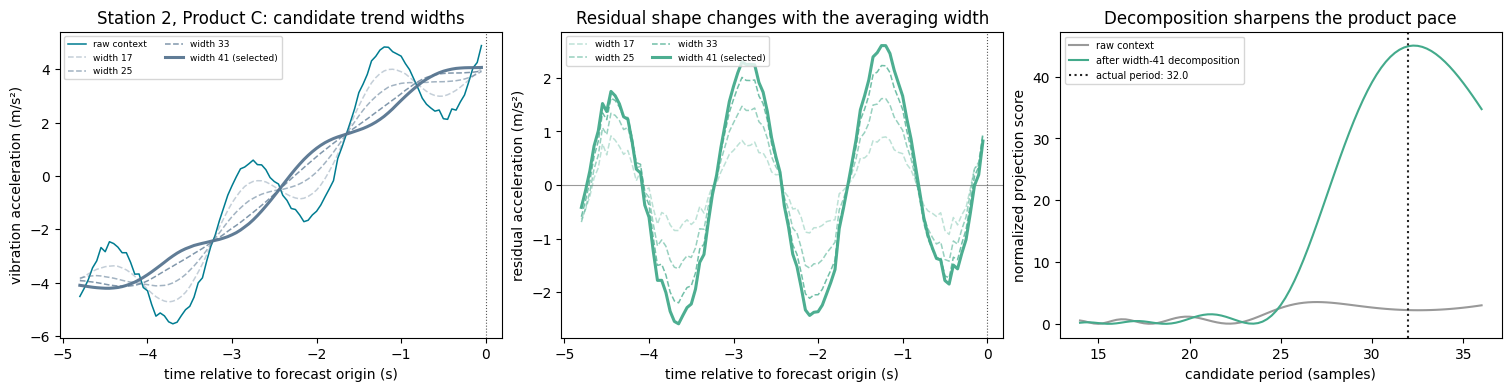

Output 2.2


,representation,oracle recovery within one sample,median absolute period error (samples),selected
0,raw,0.687,0.525,False
1,width 17,0.980,0.157,False
2,width 25,0.989,0.122,False
3,width 33,0.993,0.142,False
4,width 41,0.998,0.216,True


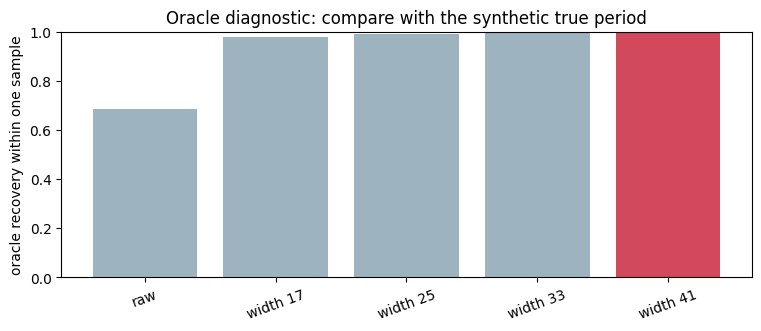

In [ ]:
assert design.check_decomposition(SeriesDecomposition)
design.register_components(decomposition_type=SeriesDecomposition)

# Supplied Part 2 model: Attention mixes the remainder; a linear head forecasts the trend.
class DecompositionAttentionBlock(nn.Module):
    def __init__(self, d, heads, kernel, decomposition_type, dropout):
        super().__init__()
        self.mix = DenseAttention(d, heads)
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.feed_forward = nn.Sequential(
            nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
        self.strip1, self.strip2 = decomposition_type(kernel), decomposition_type(kernel)

    def forward(self, x):                       # [B,L,d]
        x, _ = self.strip1(x + self.drop(self.mix(self.norm1(x))))
        x, _ = self.strip2(x + self.drop(self.feed_forward(self.norm2(x))))
        return x                               # [B,L,d]

class DecomposedAttentionForecaster(nn.Module):
    def __init__(self, context=96, horizon=48, channels=1, d=64, heads=4, layers=2,
                 kernel=25, dropout=0.1, decomposition_type=None):
        super().__init__()
        self.split = decomposition_type(kernel)
        self.trend_head = nn.Linear(context, horizon)
        self.embed = nn.Conv1d(channels, d, 3, padding=1, padding_mode="circular", bias=False)
        self.position = nn.Parameter(torch.randn(1, context, d) * 0.02)
        self.blocks = nn.ModuleList([DecompositionAttentionBlock(
            d, heads, kernel, decomposition_type, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.forecast_head = nn.Linear(context * d, horizon)

    def forward(self, context):                 # [B,L,1] -> [B,H]
        seasonal, trend = self.split(context)
        encoded = self.embed(seasonal.transpose(1, 2)).transpose(1, 2) + self.position
        for block in self.blocks:
            encoded = block(encoded)
        seasonal_forecast = self.forecast_head(self.norm(encoded).flatten(1))
        return seasonal_forecast + self.trend_head(trend.squeeze(-1))

    @property
    def attention_layers(self):
        return [block.mix for block in self.blocks]

assert design.check_decomposed_attention_assembly(DecomposedAttentionForecaster, SeriesDecomposition)
design.register_components(decomposed_attention_forecaster_type=DecomposedAttentionForecaster)
report.publish("2.1", figures.filter_decomposition(study))
report.publish("2.2", figures.recurrence_recovery(study))


In [ ]:
# Fit Attention + decomposition (Switch 1) with full per-round metrics, then Output 2.3.
train_verbose(study, "Attention + decomposition")
report.publish("2.3", figures.decomposition_ablation(study))

## 3. Mix by Temporal Delay

Switch 2 replaces the mixer rather than changing what the mixer is shown. Delay mixing scores
every delay, keeps the best few from the fixed band, sharpens them with a learned temperature,
and combines shifted copies of the context. Scoring every delay (`delay_scores`) is supplied;
you write the aggregation (`aggregate_delays`) that turns scored delays into a mixed sequence.

The mental model is: **score delays → select useful delays → shift values → combine them.**

Produces **Outputs 3.1–3.2** → used in **Response 3**.


### Delay scores (supplied)

`delay_scores(queries, keys)` takes tensors of shape `(batch, heads, features, time)` and returns
one score per delay, of shape `(batch, time)`. It is supplied below: it computes every delay's
score with two real forward FFTs and one inverse real FFT, in `O(L log L)` rather than the
`O(L^2)` a loop over delays would cost. You do not need to derive or reconstruct this procedure.

| Cell below | Output | Read it for |
| --- | --- | --- |
| the supplied scores on `[1, 3, 1, 3]`, against a direct calculation | 3.1 | Response 3 |


In [ ]:
def delay_scores(queries, keys):
    # queries, keys: [B,heads,features,L] -> scores [B,L], one per delay tau = 0 .. L-1.
    # R(tau) = sum_t q[t] * k[(t - tau) mod L], centered in time, averaged over heads and
    # features. Supplied: an FFT computes every delay's score together in O(L log L).
    queries = queries - queries.mean(-1, keepdim=True)
    keys = keys - keys.mean(-1, keepdim=True)
    spectrum = torch.fft.rfft(queries, dim=-1) * torch.fft.rfft(keys, dim=-1).conj()
    return torch.fft.irfft(spectrum, n=queries.shape[-1], dim=-1).mean((1, 2))


In [ ]:
# delay_scores is supplied above. This toy example confirms it against a direct circular
# correlation for q = k = [1, 3, 1, 3], which centers to [-1, 1, -1, 1].
example = torch.tensor([1., 3., 1., 3.]).reshape(1, 1, 1, 4)
scores = pd.DataFrame({"delay": range(4),
                       "delay_scores (FFT)": delay_scores(example, example).flatten().tolist(),
                       "direct circular correlation": [4., -4., 4., -4.]})
display(scores.round(6))

assert design.check_delay_scores(delay_scores)
design.register_components(delay_scores=delay_scores)
report.publish("3.1", scores)


### Delay aggregation

`aggregate_delays(values, delays, weights)` takes `values` of shape
`(batch, heads, features, time)` plus `delays` and `weights` of shape `(batch, K)`, and returns the
weighted circular shifts, of shape `(batch, heads, features, time)` — the same shape as `values`.

Position `t` reads the value from `t - delay`, wrapping modulo `L`. Each example carries its own
delays and weights, shared across that example's heads and features.

The worked example below is the handout's aggregation case, and its first entry decides the direction:
`z0 = 35` means your shift runs the right way, `z0 = 25` means it runs backwards. That is the
single most common bug in this cell.

The next cell checks this aggregation immediately with the worked example and a gradient test.


In [ ]:
def aggregate_delays(values, delays, weights):
    # values: [B,heads,features,L]; delays, weights: [B,K] -> [B,heads,features,L]
    # Equation (6):  z[t] = sum_j weights[b,j] * values[b, :, :, (t - delays[b,j]) mod L]
    # Each example b has its OWN K selected delays and weights, shared across that
    # example's heads and features. Must stay differentiable in values AND weights.
    # ============================== IMPLEMENTATION ==============================
    batch, heads, features, length = values.shape
    positions = torch.arange(length, device=values.device)        # t = 0..L-1  -> [L]
    out = torch.zeros_like(values)                                # accumulator [B,h,f,L]
    for j in range(delays.shape[1]):                              # K is small (K = ceil(2 ln L))
        # DIRECTION (the classic bug): position t must READ from t - delay, so the
        # source index is (t - delay) mod L. Building it as (t - delay) rolls the
        # sequence FORWARD, which is why the worked example gives z0 = 35 (not 25).
        source = (positions[None, :] - delays[:, j:j + 1]) % length            # [B, L]
        # Gather needs an index tensor matching values' shape; broadcast the per-
        # example source index across the head and feature axes.
        index = source[:, None, None, :].expand(batch, heads, features, length).long()  # [B,h,f,L]
        gathered = torch.gather(values, -1, index)               # circularly shifted values
        # Weight this delay's contribution (per example) and accumulate. gather and
        # the multiply are both differentiable, so gradients reach values and weights.
        out = out + weights[:, j][:, None, None, None] * gathered
    return out
    # ===========================================================================


In [ ]:
# Let v = [10, 20, 30, 40], delays [1, 3], and weights [3/4, 1/4].
# z0 = 3/4 * v[3] + 1/4 * v[1] = 30 + 5 = 35. If you get 25, the shift runs the wrong way.
values = torch.tensor([10., 20., 30., 40.]).reshape(1, 1, 1, 4)
mixed = aggregate_delays(values, torch.tensor([[1, 3]]), torch.tensor([[.75, .25]]))
aggregated = pd.DataFrame({"position": range(4),
                           "your aggregated value": mixed.flatten(),
                           "expected": [35., 15., 25., 25.]})
display(aggregated.round(6))

assert design.check_aggregation(aggregate_delays)
design.register_components(aggregate=aggregate_delays)


### Delay mixer (supplied)

`DelayMixer` applies the full sequence: it projects the context into q/k/v features, calls the
supplied scorer, selects useful delays, and calls your aggregation function to combine the
shifted values.


In [ ]:
class DelayMixer(nn.Module):
    def __init__(self, d, heads, delay_score_fn, aggregate_fn, min_delay=8, max_delay=48):
        super().__init__()
        if d % heads:
            raise ValueError("width must be divisible by heads")
        self.heads, self.min_delay, self.max_delay = heads, min_delay, max_delay
        self.delay_score_fn, self.aggregate_fn = delay_score_fn, aggregate_fn
        self.query, self.key, self.value = (nn.Linear(d, d) for _ in range(3))
        self.out = nn.Linear(d, d)
        self.raw_temperature = nn.Parameter(torch.tensor(0.5413248546))

    @property
    def temperature(self):
        return F.softplus(self.raw_temperature) + 1e-6

    def forward(self, x):                       # [B,L,d]
        batch, length, width = x.shape
        shape = (batch, length, self.heads, width // self.heads)
        q, k, v = (layer(x).view(shape).permute(0, 2, 3, 1)
                   for layer in (self.query, self.key, self.value))  # [B,h,d_h,L]
        scores = self.delay_score_fn(q, k)      # [B,L]
        lo, hi = self.min_delay, min(self.max_delay, length - 1)
        band = scores[:, lo:hi + 1]
        top_k = min(math.ceil(2 * math.log(length)), band.shape[-1])
        selected, indices = band.topk(top_k, dim=-1)
        delays = indices + lo                  # [B,K]
        weights = (selected / self.temperature).softmax(-1)  # [B,K]
        mixed = self.aggregate_fn(v, delays, weights)         # [B,h,d_h,L]
        return self.out(mixed.permute(0, 3, 1, 2).reshape(batch, length, width))


### Output 3.2 — Signal-level recurrence diagnostic

This diagnostic correlates raw and residual **signal values** directly. It does **not** show the
trained mixer's learned q/k delay scores. It makes the repeating-delay assumption visible; the
model scores learned projected features.


In [ ]:
recurrence = figures.delay_recurrence(study)
report.publish("3.2", recurrence)


## 4. Compare Designs and Deploy

Nothing new to implement. Before running Output 4.1, write the prediction requested in
**Response 4** in at most two sentences. You now know both switches, so this part introduces the
supplied unified network. The four models are that one network with the two switches thrown
differently. The combined decomposed-delay configuration is called **Autoformer-inspired**.
They share width, depth, data order, optimizer schedule, and
checkpoint policy; they do **not** share parameter count or runtime, which Output 4.1 reports in
separate columns.

Produces **Outputs 4.1–4.3** → used in **Response 4**.

| Cell below | Output | Read it for |
| --- | --- | --- |
| fit the two remaining models; comparison table and contrasting forecast cases | 4.1 | Response 4 — write its prediction first |
| error along the 48-step horizon | 4.2 | Response 4 |
| selected models and their validation/test results | 4.3 | Response 4 |


In [ ]:
# Supplied unified 2x2 design.
class IdentitySplit(nn.Module):
    def forward(self, x):
        return x, torch.zeros_like(x)

class EncoderBlock(nn.Module):
    def __init__(self, d, heads, mixing, kernel, decomposition_type,
                 delay_score_fn, aggregate_fn, dropout):
        super().__init__()
        self.mix = (DelayMixer(d, heads, delay_score_fn, aggregate_fn)
                    if mixing == "delay" else DenseAttention(d, heads))
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.feed_forward = nn.Sequential(
            nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
        split = decomposition_type if decomposition_type is not None else lambda _: IdentitySplit()
        self.strip1, self.strip2 = split(kernel), split(kernel)

    def forward(self, x):                       # [B,L,d]
        x, _ = self.strip1(x + self.drop(self.mix(self.norm1(x))))
        x, _ = self.strip2(x + self.drop(self.feed_forward(self.norm2(x))))
        return x                               # [B,L,d]

class AutoformerInspiredForecaster(nn.Module):
    def __init__(self, context=96, horizon=48, channels=1, d=64, heads=4, layers=2,
                 mixing="attention", representation="raw", kernel=25, dropout=0.1,
                 decomposition_type=None, delay_score_fn=None, aggregate_fn=None):
        super().__init__()
        if representation not in {"raw", "decomposed"}:
            raise ValueError("representation must be 'raw' or 'decomposed'")
        self.split = (decomposition_type(kernel) if representation == "decomposed"
                      else IdentitySplit())
        self.trend_head = nn.Linear(context, horizon) if representation == "decomposed" else None
        self.embed = nn.Conv1d(channels, d, 3, padding=1, padding_mode="circular", bias=False)
        self.position = nn.Parameter(torch.randn(1, context, d) * 0.02)
        self.blocks = nn.ModuleList([EncoderBlock(
            d, heads, mixing, kernel, decomposition_type, delay_score_fn, aggregate_fn, dropout)
            for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.forecast_head = nn.Linear(context * d, horizon)

    def forward(self, context):                 # [B,L,1] -> [B,H]
        seasonal, trend = self.split(context)
        encoded = self.embed(seasonal.transpose(1, 2)).transpose(1, 2) + self.position
        for block in self.blocks:
            encoded = block(encoded)
        seasonal_forecast = self.forecast_head(self.norm(encoded).flatten(1))
        trend_forecast = 0 if self.trend_head is None else self.trend_head(trend.squeeze(-1))
        return seasonal_forecast + trend_forecast

    @property
    def attention_layers(self):
        return [block.mix for block in self.blocks if isinstance(block.mix, DenseAttention)]

    @property
    def delay_layers(self):
        return [block.mix for block in self.blocks if isinstance(block.mix, DelayMixer)]

assert design.check_assembly(AutoformerInspiredForecaster)
design.register_components(forecaster_type=AutoformerInspiredForecaster)
# Fit the two remaining 2x2 models with the comprehensive per-round metric panel.
train_verbose(study, "Raw delay mixer")
train_verbose(study, "Autoformer-inspired")
cases = figures.contrasting_forecasts(study)
report.publish("4.1", report.comparison(study, [
    "Raw Attention", "Raw delay mixer", "Attention + decomposition", "Autoformer-inspired"]))
display(cases.round(3))

In [ ]:
report.publish("4.2", figures.horizon_figure(study, [
    "Period-routed ridge", "Raw Attention", "Raw delay mixer",
    "Attention + decomposition", "Autoformer-inspired"]))


### Choose the deployment models (Response 4)

Choose one fitted model for the established stations and one for held-out station 4 using validation
MSE, physical-unit RMSE, parameter count, and fitting time,
then enter both model names below. Output 4.3 reports their validation and test results.

The compact validation-only decision summary below collects the error and cost quantities needed
for this choice. It is not another Output; Outputs 1.1 and 4.1–4.2 remain the detailed evidence.

| Cell below | Output | Read it for |
| --- | --- | --- |
| enter both choices | — | Response 4 |
| validation/test results for both choices | 4.3 | Response 4 |


In [ ]:
# Validation-only decision summary.
display(report.deployment_summary(study).round(3))


In [ ]:
# Response 4(c): choose ONE deployment model per population from the VALIDATION
# evidence above (deployment_summary + Outputs 1.1 / 4.1 / 4.2): validation MSE &
# physical-unit RMSE, parameter count, and fitting time. Confirm these two names
# against the numbers printed above and edit them if your run disagrees.
#
# Default reasoning (verify against your PA1_PRESET=full run):
#  * established stations 1-3 -> "Attention + decomposition". Decomposition
#    (Switch 1) removes the slow ramp that otherwise crowds the encoder, and in
#    this drift+repetition world it captures most of the achievable gain; adding
#    delay mixing on top (Autoformer-inspired) tends to overlap rather than stack,
#    so the decomposed-Attention model is the better accuracy-per-parameter /
#    per-second deployment. Switch to "Autoformer-inspired" only if it shows a
#    clear validation-RMSE win that pays for its extra cost.
#  * held-out station 4 -> "Period-routed ridge". Sensor-specific ridge is
#    unavailable for an unseen station, and period routing conditions on operating
#    pace (not station identity), so it generalises to station 4 at essentially
#    zero fitting cost. It is the principled, cheapest choice for the unseen case;
#    prefer a decomposed neural model only if it beats it on station-4 validation.
choices = {
    "established": "Attention + decomposition",
    "held-out":   "Period-routed ridge",
}
display(study.select_for_test(choices))

In [ ]:
report.publish("4.3", study.selected_test_table())
